In [17]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img

DATA_DIR = '/kaggle/input/datasets/shlyapa88man/synthetic-pipe-dataset/pipe_dataset'
OUTPUT_DIR = '/kaggle/working'
IMG_SIZE = 224
BATCH_SIZE = 32
N_CLASSES = 6
EPOCHS = 20
SEED = 42


def gaussian_noise(sigma):
    def add_noise(image):
        return np.clip(image + np.random.normal(0, sigma, image.shape), 0, 255)
    return add_noise


CONFIGS = {
    'Без аугментации': {},
    'Поворот': {'rotation_range': 20, 'fill_mode': 'nearest'},
    'Яркость': {'brightness_range': [0.8, 1.2]},
    'Шум': {'preprocessing_function': gaussian_noise(15)},
    'Избыточная': {
        'rotation_range': 160,
        'brightness_range': [0.2, 2.0],
        'preprocessing_function': gaussian_noise(60),
        'fill_mode': 'nearest'
    }
}

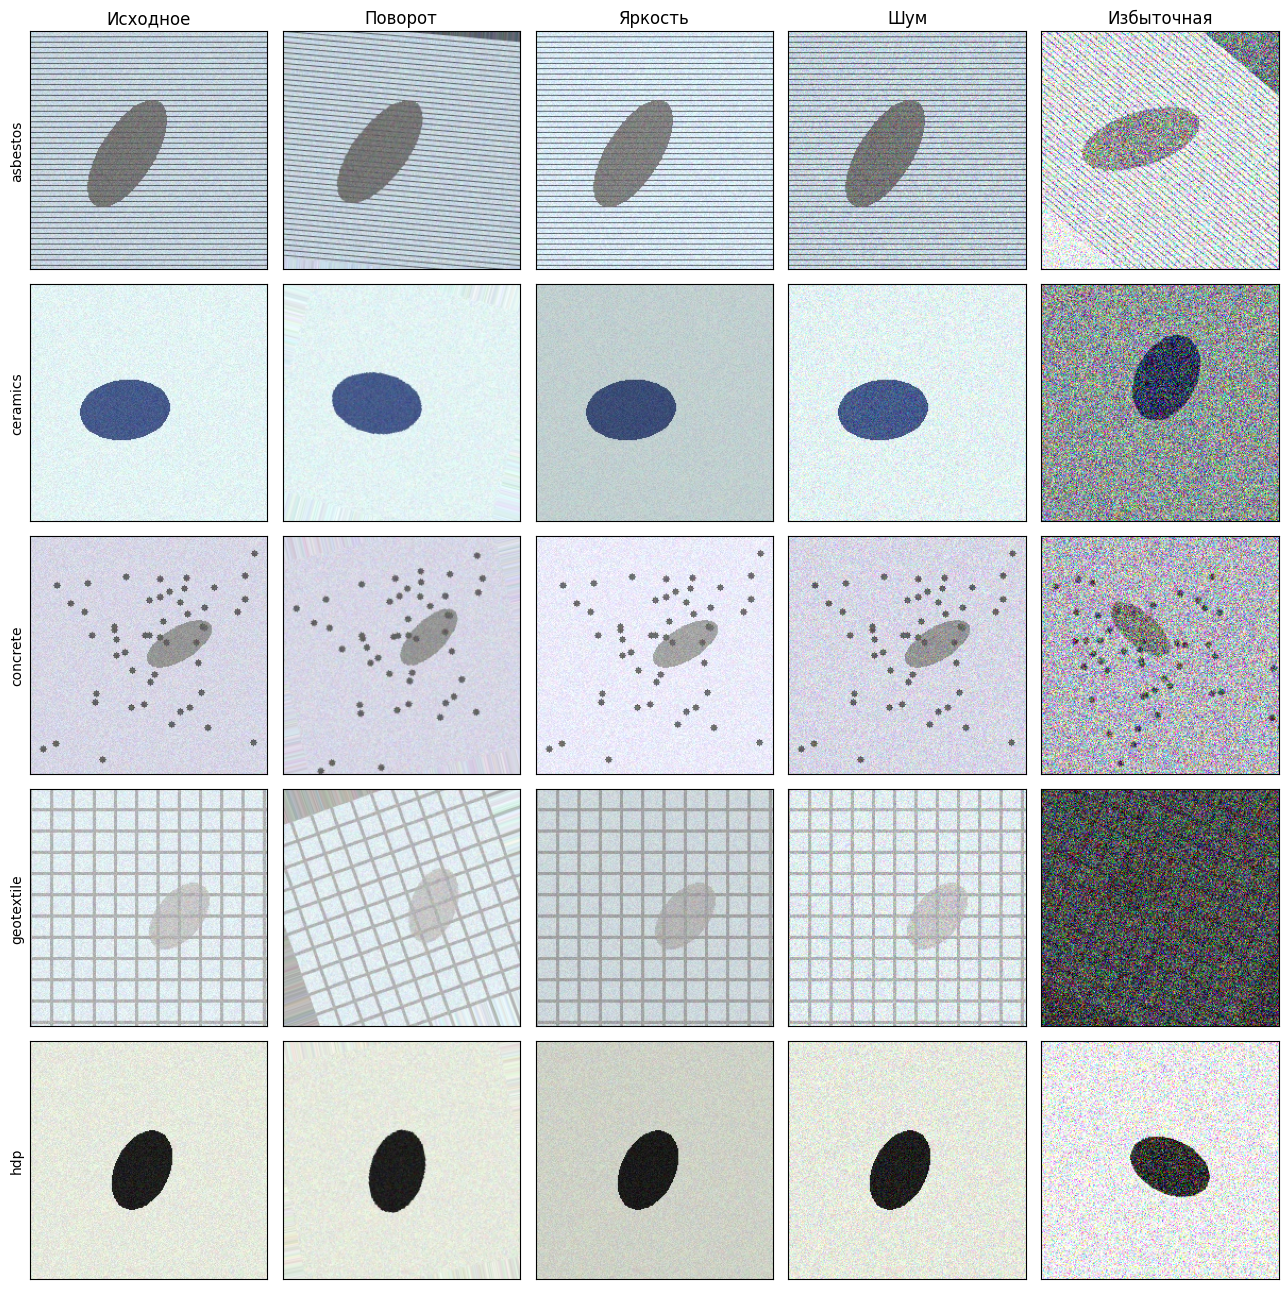

In [18]:
def show_augmented_examples(n_images=5, filename='augmentation_examples.png'):
    names = [name for name in CONFIGS if name != 'Без аугментации']
    train_dir = os.path.join(DATA_DIR, 'train')
    classes = sorted(os.listdir(train_dir))[:n_images]

    fig, axes = plt.subplots(n_images, len(names) + 1, figsize=(2.6 * (len(names) + 1), 2.6 * n_images))
    for row, class_name in enumerate(classes):
        class_dir = os.path.join(train_dir, class_name)
        path = os.path.join(class_dir, sorted(os.listdir(class_dir))[0])
        image = img_to_array(load_img(path, target_size=(IMG_SIZE, IMG_SIZE)))

        axes[row, 0].imshow(image / 255.0)
        axes[row, 0].set_title('Исходное' if row == 0 else '')
        axes[row, 0].set_ylabel(class_name)
        for col, name in enumerate(names, start=1):
            np.random.seed(SEED + row)
            datagen = ImageDataGenerator(rescale=1. / 255, **CONFIGS[name])
            augmented = next(datagen.flow(image[np.newaxis], batch_size=1, seed=SEED + row))[0]
            axes[row, col].imshow(np.clip(augmented, 0, 1))
            axes[row, col].set_title(name if row == 0 else '')
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=150)
    plt.show()


show_augmented_examples()

In [19]:
def make_generator(subset, params, shuffle):
    datagen = ImageDataGenerator(rescale=1. / 255, **params)
    return datagen.flow_from_directory(
        os.path.join(DATA_DIR, subset),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=shuffle,
        seed=SEED
    )


def build_model():
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base_model.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(N_CLASSES, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


histories = {}
results = []

for name, params in CONFIGS.items():
    print(f"\n=== {name} ===")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    train_generator = make_generator('train', params, shuffle=True)
    val_generator = make_generator('val', {}, shuffle=False)

    model = build_model()
    history = model.fit(train_generator, validation_data=val_generator, epochs=EPOCHS, verbose=2)
    histories[name] = history.history

    results.append({
        'Аугментация': name,
        'train_accuracy': history.history['accuracy'][-1],
        'val_accuracy': history.history['val_accuracy'][-1],
        'val_loss': history.history['val_loss'][-1]
    })
    del model


=== Без аугментации ===
Found 900 images belonging to 6 classes.
Found 132 images belonging to 6 classes.
Epoch 1/20
29/29 - 21s - 738ms/step - accuracy: 0.7633 - loss: 0.6360 - val_accuracy: 0.9621 - val_loss: 0.1489
Epoch 2/20
29/29 - 4s - 128ms/step - accuracy: 0.9056 - loss: 0.2204 - val_accuracy: 0.9773 - val_loss: 0.0953
Epoch 3/20
29/29 - 4s - 131ms/step - accuracy: 0.9533 - loss: 0.1177 - val_accuracy: 0.9773 - val_loss: 0.0828
Epoch 4/20
29/29 - 4s - 124ms/step - accuracy: 0.9656 - loss: 0.0968 - val_accuracy: 0.9848 - val_loss: 0.0628
Epoch 5/20
29/29 - 4s - 132ms/step - accuracy: 0.9767 - loss: 0.0656 - val_accuracy: 0.9773 - val_loss: 0.0565
Epoch 6/20
29/29 - 4s - 124ms/step - accuracy: 0.9778 - loss: 0.0636 - val_accuracy: 0.9697 - val_loss: 0.0959
Epoch 7/20
29/29 - 4s - 127ms/step - accuracy: 0.9756 - loss: 0.0690 - val_accuracy: 0.9773 - val_loss: 0.0403
Epoch 8/20
29/29 - 3s - 120ms/step - accuracy: 0.9833 - loss: 0.0499 - val_accuracy: 0.9773 - val_loss: 0.0569
Epoc

In [20]:
def plot_curves(names, filename, title, show_train=False):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, metric, metric_title in zip(axes, ['accuracy', 'loss'], ['Accuracy', 'Loss']):
        for name in names:
            epochs = range(1, EPOCHS + 1)
            line, = ax.plot(epochs, histories[name][f'val_{metric}'], label=f'{name}: валидация')
            if show_train:
                ax.plot(epochs, histories[name][metric], '--', color=line.get_color(), alpha=0.6,
                        label=f'{name}: обучение')
        ax.set_title(f'{metric_title}: {title}')
        ax.set_xlabel('Эпоха')
        ax.set_ylabel(metric_title)
        ax.grid(True, alpha=0.3)

    handles, labels = axes[0].get_legend_handles_labels()
    plt.tight_layout()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0),
               ncol=len(names), fontsize=10, frameon=False)
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=150, bbox_inches='tight')
    plt.show()

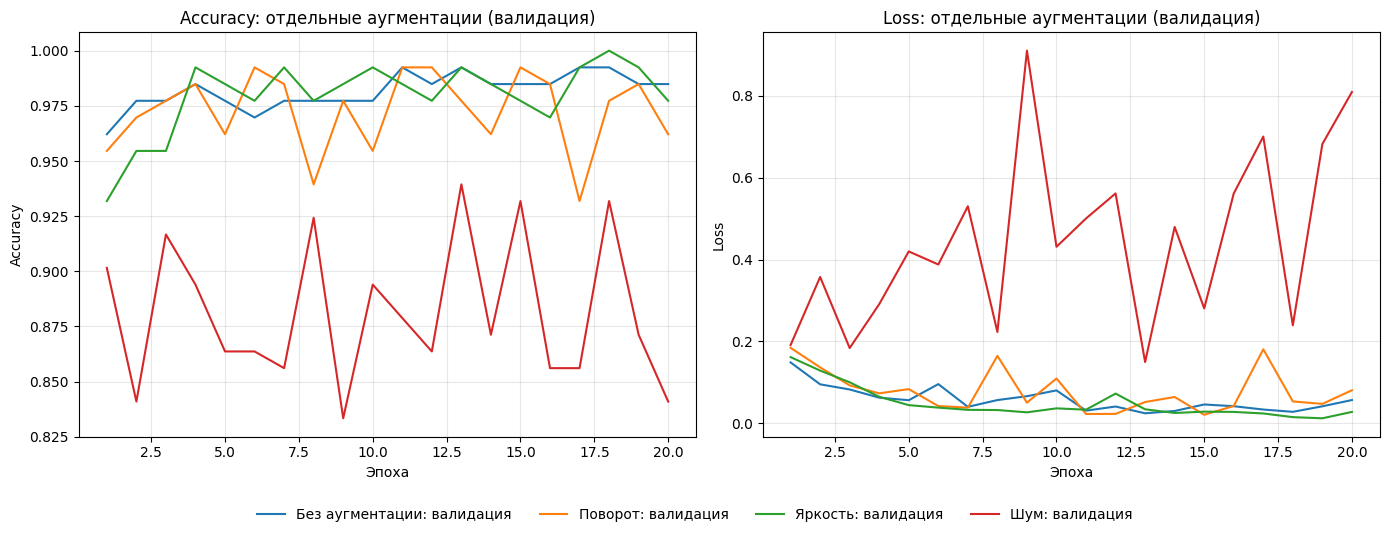

In [21]:
plot_curves(['Без аугментации', 'Поворот', 'Яркость', 'Шум'], 'augmentation_by_type.png',
            'отдельные аугментации (валидация)')

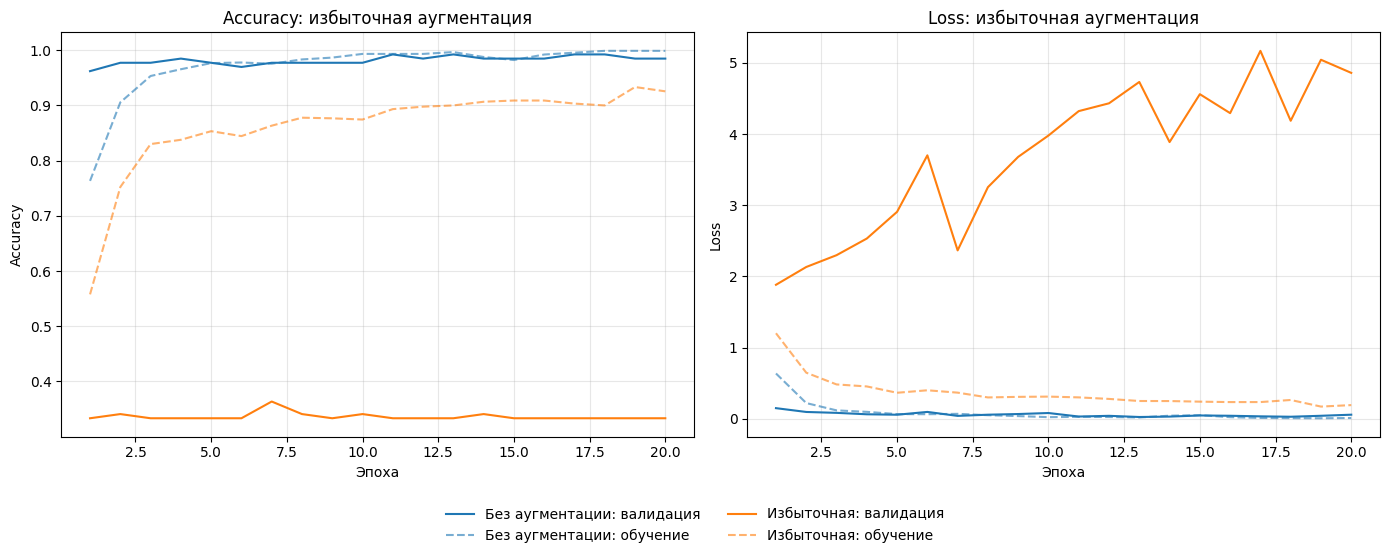

In [22]:
plot_curves(['Без аугментации', 'Избыточная'], 'augmentation_excessive.png',
            'избыточная аугментация', show_train=True)